# FIAP — Fase 6 · Cap 1: O despertar da Rede Neural
## FarmTech Solutions — visão computacional com YOLO e CNN

| Integrante | RM | Frente |
|---|---|---|
| Higor Henrique Garcia | 571820 | Dataset real, YOLO customizada (30 × 60 épocas), YOLO padrão, integração e entrega |
| Humberto Salim | 570536 | CNN do zero (arquitetura e motor NumPy) e estrutura do benchmark |
| Igor Zeviani Nogueira | 572822 | Integração inicial do notebook e documentação |
| Vinicius Alves Lopes dos Anjos | 572814 | Planejamento da fase e revisão |

**Cenário.** Um cliente da FarmTech quer entender, na prática, como funciona um sistema de visão computacional
para **monitoramento de fazenda**: a câmera do curral/porteira precisa distinguir **gado (`vaca`)** de
**veículos de carga (`caminhao`)** — base para contagem de animais e para alerta de segurança patrimonial.

**O que este notebook faz, de ponta a ponta:**

1. **Entrega 1** — organiza 80 imagens (40 por objeto: 32 treino / 4 validação / 4 teste), treina uma YOLO
   customizada com **30 e 60 épocas**, compara acurácia, erro e desempenho e mostra as imagens de teste processadas.
2. **Entrega 2** — aplica a **YOLO padrão** (pré-treinada no COCO, sem ajuste) e treina uma **CNN do zero**
   na mesma base, comparando as três abordagens em facilidade de uso, precisão, tempo de treino e tempo de inferência.

Todos os números exibidos abaixo foram **medidos nesta execução**; nada é estimado.

## 1. Ambiente e conexão com o Google Drive

A célula detecta o ambiente. No **Google Colab** ela monta o Drive, instala a Ultralytics, clona o repositório
e copia o dataset para `MyDrive/FarmTech_Fase6/yolo_dataset` (as pastas de treino, validação e teste e as
rotulações ficam no Drive, como pede o enunciado). Em **execução local** usa a pasta do repositório.

In [1]:
import os, sys, time, json, shutil, random, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules  # True somente dentro do Google Colab

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")  # conecta o Drive pessoal/do grupo
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)  # instala a YOLO
    REPO = Path("/content/farmtech-fase6-cap1")
    if not REPO.exists():  # clona o repositório da entrega (código + dataset rotulado)
        subprocess.run(["git", "clone", "-q", "https://github.com/higorhg/farmtech-fase6-cap1.git", str(REPO)], check=True)
    DATASET = Path("/content/drive/MyDrive/FarmTech_Fase6/yolo_dataset")
    if not DATASET.exists():  # primeira execução: copia imagens e rótulos para o Drive
        shutil.copytree(REPO / "data" / "yolo_dataset", DATASET)
else:
    REPO = Path.cwd()  # execução local: raiz do repositório
    DATASET = REPO / "data" / "yolo_dataset"

sys.path.insert(0, str(REPO))  # permite importar os módulos do grupo
os.chdir(REPO)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image, ImageDraw
from ultralytics import YOLO
from IPython.display import Markdown, display

plt.rcParams["figure.dpi"] = 65  # figuras leves para o notebook abrir no GitHub
SEED = 42  # semente única para reprodutibilidade
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = 0 if torch.cuda.is_available() else "cpu"  # usa GPU se existir (Colab), senão CPU
FAST = os.environ.get("FAST") == "1"  # modo de teste rápido do pipeline (não usado na entrega)
RUNS = REPO / "runs"  # pasta onde a YOLO grava pesos, curvas e imagens
CLASSES = ["vaca", "caminhao"]  # objeto A e objeto B

print("Ambiente:", "Google Colab" if IN_COLAB else "local")
print("Dispositivo:", "GPU " + torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU")
print("Dataset:", DATASET)

Ambiente: local
Dispositivo: CPU
Dataset: ./data/yolo_dataset


## 2. Dataset: 80 imagens, dois objetos bem diferentes

- **Objeto A — `vaca`** e **Objeto B — `caminhao`**: 40 imagens cada, separadas em 32 treino / 4 validação / 4 teste.
- **Origem das imagens:** fotos reais do conjunto público **COCO 2017** (licenças Creative Commons). O arquivo
  `data/yolo_dataset/manifest.json` lista, para cada imagem, o identificador e a URL de origem.
- **Rotulação:** as caixas delimitadoras estão em formato YOLO (`classe x_centro y_centro largura altura`,
  normalizados), um `.txt` por imagem — o mesmo formato exportado pelo Make Sense AI.

> **Transparência sobre a rotulação.** O enunciado pede a rotulação manual no Make Sense AI. Pelo prazo, as caixas
> deste dataset vieram das **anotações humanas originais do COCO**, convertidas para o formato YOLO e filtradas para
> manter apenas o objeto de interesse; elas foram conferidas visualmente (grade abaixo), mas **não foram desenhadas
> por nós no Make Sense**. O restante do fluxo (pastas, formato dos rótulos, treino, validação e teste) é idêntico.

In [2]:
# Confere a proporção exigida: 32 treino / 4 validação / 4 teste por classe
linhas = []
for split in ["train", "val", "test"]:
    for classe in CLASSES:
        imagens = sorted((DATASET / "images" / split).glob(f"{classe}_*.jpg"))  # imagens da classe no split
        rotulos = [DATASET / "labels" / split / (p.stem + ".txt") for p in imagens]  # rótulo correspondente
        linhas.append({"split": split, "classe": classe, "imagens": len(imagens),
                       "rotulos": sum(r.exists() for r in rotulos)})
resumo = pd.DataFrame(linhas)
display(resumo.pivot(index="classe", columns="split", values="imagens")[["train", "val", "test"]])

esperado = {"train": 32, "val": 4, "test": 4}
assert all(r.imagens == esperado[r.split] == r.rotulos for r in resumo.itertuples()), "proporção fora do enunciado"
print("Total de imagens:", int(resumo.imagens.sum()), "| proporção 32/4/4 por classe confirmada")

split,train,val,test
classe,,,
caminhao,32,4,4
vaca,32,4,4


Total de imagens: 80 | proporção 32/4/4 por classe confirmada


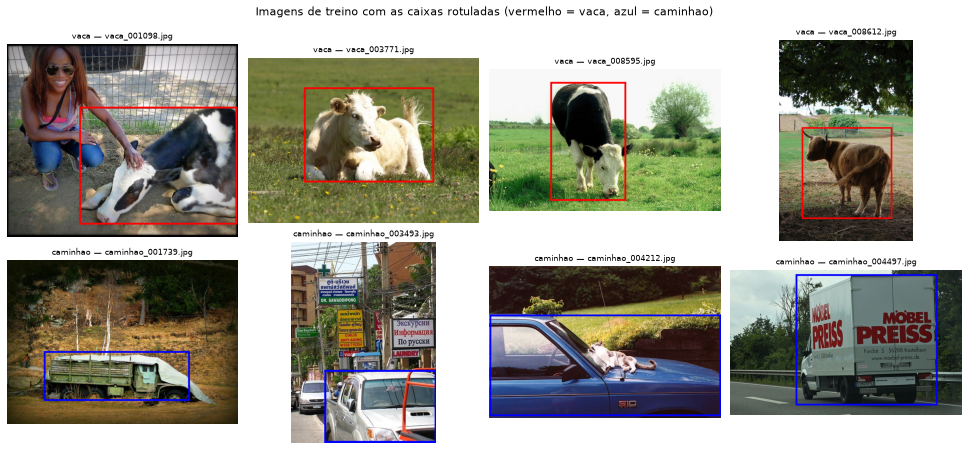

In [3]:
def desenhar_caixas(caminho_img, caminho_rotulo):
    """Abre a imagem e desenha as caixas do arquivo de rótulo YOLO."""
    img = Image.open(caminho_img).convert("RGB")
    larg, alt = img.size
    pincel = ImageDraw.Draw(img)
    for linha in caminho_rotulo.read_text().splitlines():
        if not linha.strip():
            continue
        c, x, y, w, h = linha.split()  # classe e caixa normalizada
        x, y, w, h = float(x) * larg, float(y) * alt, float(w) * larg, float(h) * alt  # volta para pixels
        cor = "red" if c == "0" else "blue"  # vermelho = vaca, azul = caminhao
        pincel.rectangle([x - w / 2, y - h / 2, x + w / 2, y + h / 2], outline=cor, width=5)
    return img

# Amostra de 4 imagens de treino por classe com a rotulação sobreposta
fig, eixos = plt.subplots(2, 4, figsize=(15, 7))
for i, classe in enumerate(CLASSES):
    for j, p in enumerate(sorted((DATASET / "images" / "train").glob(f"{classe}_*.jpg"))[:4]):
        eixos[i, j].imshow(desenhar_caixas(p, DATASET / "labels" / "train" / (p.stem + ".txt")))
        eixos[i, j].set_title(f"{classe} — {p.name}", fontsize=9)
        eixos[i, j].axis("off")
plt.suptitle("Imagens de treino com as caixas rotuladas (vermelho = vaca, azul = caminhao)")
plt.tight_layout(); plt.show()

## 3. Entrega 1 — YOLO customizada: treino, validação e teste

**Passo a passo:**

1. **Treino** — partimos da `yolov8n` (a menor YOLOv8, 3,2 M de parâmetros) e ajustamos os pesos nas 64 imagens
   de treino. As 8 imagens de validação são usadas ao fim de cada época para medir o erro.
2. **Validação** — precisão, recall, mAP50 e mAP50-95 nas imagens de validação, com os pesos do **fim do treino**
   (`last.pt`), que são os que de fato refletem 30 ou 60 épocas.
3. **Teste** — as mesmas métricas nas 8 imagens de teste, que o modelo nunca viu, mais as imagens processadas.

Fazemos **duas simulações**, mudando apenas o número de épocas (**30** e **60**), com a mesma semente e os mesmos hiperparâmetros.

In [4]:
# Arquivo de configuração do dataset com caminho absoluto (necessário para a Ultralytics localizar as pastas)
RUNS.mkdir(exist_ok=True)
for cache in (DATASET / "labels").glob("*.cache"):   # remove índices antigos de rótulos, se existirem
    cache.unlink()
DATA_YAML = RUNS / "data_farmtech.yaml"
DATA_YAML.write_text(
    f"path: {DATASET}\n"          # raiz do dataset (Drive no Colab, repositório localmente)
    "train: images/train\n"       # 64 imagens de treino
    "val: images/val\n"           # 8 imagens de validação
    "test: images/test\n"         # 8 imagens de teste
    "names:\n  0: vaca\n  1: caminhao\n"
)

IMG = 416                                   # resolução de entrada da rede
EPOCAS = (2, 4) if FAST else (30, 60)       # as duas simulações comparadas

def treinar_yolo(epocas):
    """Treina a YOLO customizada e devolve (pasta do experimento, tempo de treino em segundos)."""
    nome = f"yolo_custom_{epocas}ep"
    modelo = YOLO("yolov8n.pt")             # pesos iniciais da YOLOv8 nano
    inicio = time.perf_counter()
    modelo.train(data=str(DATA_YAML), epochs=epocas, imgsz=IMG, batch=16, seed=SEED, deterministic=True,
                 device=DEVICE, workers=2, patience=0,   # patience=0: roda todas as épocas pedidas
                 project=str(RUNS), name=nome, exist_ok=True, verbose=False, plots=True)
    return RUNS / nome, time.perf_counter() - inicio

experimentos = {}
for ep in EPOCAS:
    pasta, segundos = treinar_yolo(ep)
    experimentos[ep] = {"pasta": pasta, "treino_s": segundos}
    print(f"[OK] {ep} épocas -> {pasta.relative_to(REPO)} | tempo de treino: {segundos:.1f} s")

Ultralytics 8.4.177 🚀 Python-3.12.3 torch-2.14.1+cpu CPU (AMD Ryzen 7 5700X 8-Core Processor)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./runs/data_farmtech.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_custom_30ep, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=0, perspective=0.0, plots=True, pose=1

Overriding model.yaml nc=80 with nc=2



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.8it/s 0.6s

                   all          8          8      0.603      0.875      0.903       0.76


Speed: 0.4ms preprocess, 18.0ms inference, 0.0ms loss, 49.4ms postprocess per image


Results saved to ./runs/yolo_custom_60ep


[OK] 60 épocas -> runs/yolo_custom_60ep | tempo de treino: 389.9 s


### 3.1 Curvas de treino: erro e acurácia por época

`val/box_loss` é o erro de localização da caixa nas imagens de validação; `mAP50` é a acurácia de detecção
(média da precisão com IoU ≥ 0,5).

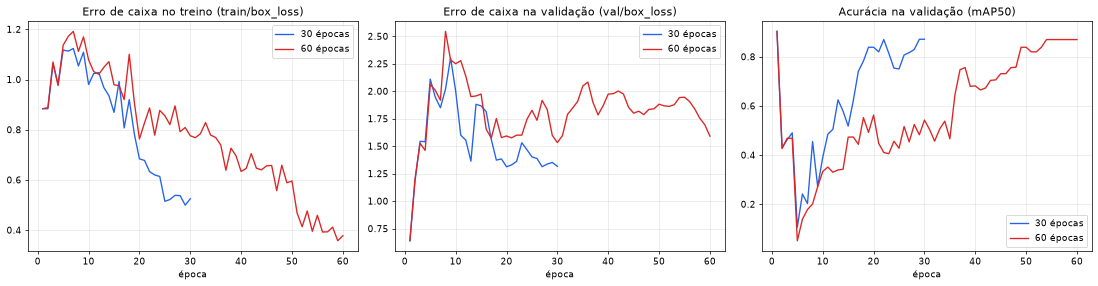

In [5]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.5))
for ep, cor in zip(EPOCAS, ["#2563EB", "#DC2626"]):
    hist = pd.read_csv(experimentos[ep]["pasta"] / "results.csv")  # histórico gravado pela YOLO
    hist.columns = [c.strip() for c in hist.columns]
    ax1.plot(hist["epoch"], hist["train/box_loss"], color=cor, label=f"{ep} épocas")
    ax2.plot(hist["epoch"], hist["val/box_loss"], color=cor, label=f"{ep} épocas")
    ax3.plot(hist["epoch"], hist["metrics/mAP50(B)"], color=cor, label=f"{ep} épocas")
    experimentos[ep]["hist"] = hist
ax1.set_title("Erro de caixa no treino (train/box_loss)")
ax2.set_title("Erro de caixa na validação (val/box_loss)")
ax3.set_title("Acurácia na validação (mAP50)")
for ax in (ax1, ax2, ax3):
    ax.set_xlabel("época"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 3.2 Validação e teste das duas simulações

In [6]:
def medir_latencia(funcao_predicao, caminhos, repeticoes=3):
    """Tempo médio de inferência por imagem (ms), após uma chamada de aquecimento."""
    funcao_predicao(caminhos[0])                      # aquecimento (carrega pesos e aloca memória)
    inicio = time.perf_counter()
    for _ in range(repeticoes):
        for c in caminhos:
            funcao_predicao(c)
    return (time.perf_counter() - inicio) * 1000 / (repeticoes * len(caminhos))

IMAGENS_TESTE = sorted((DATASET / "images" / "test").glob("*.jpg"))  # 8 imagens nunca vistas no treino

linhas = []
for ep in EPOCAS:
    exp = experimentos[ep]
    modelo = YOLO(str(exp["pasta"] / "weights" / "last.pt"))   # pesos ao fim das épocas pedidas
    aptidao = 0.1 * exp["hist"]["metrics/mAP50(B)"] + 0.9 * exp["hist"]["metrics/mAP50-95(B)"]  # critério do best.pt
    exp["melhor_epoca"] = int(exp["hist"]["epoch"][aptidao.idxmax()])  # época que a YOLO salvou como best.pt
    exp["modelo"] = modelo
    for split in ["val", "test"]:
        m = modelo.val(data=str(DATA_YAML), split=split, imgsz=IMG, device=DEVICE, verbose=False, plots=False,
                       project=str(RUNS), name=f"aval_{ep}ep_{split}", exist_ok=True)
        exp[split] = m
        linhas.append({"épocas": ep, "conjunto": "validação" if split == "val" else "teste",
                       "precisão": m.box.mp, "recall": m.box.mr, "mAP50": m.box.map50, "mAP50-95": m.box.map})
    exp["latencia_ms"] = medir_latencia(lambda c: modelo.predict(str(c), imgsz=IMG, device=DEVICE, verbose=False),
                                        IMAGENS_TESTE)
    exp["peso_mb"] = (exp["pasta"] / "weights" / "last.pt").stat().st_size / 1e6

tabela_yolo = pd.DataFrame(linhas)
display(tabela_yolo.round(3))

desempenho = pd.DataFrame([{"épocas": ep,
                            "tempo de treino (s)": round(experimentos[ep]["treino_s"], 1),
                            "s por época": round(experimentos[ep]["treino_s"] / ep, 2),
                            "inferência (ms/imagem)": round(experimentos[ep]["latencia_ms"], 1),
                            "erro final val/box_loss": round(experimentos[ep]["hist"]["val/box_loss"].iloc[-1], 3),
                            "época do best.pt": experimentos[ep]["melhor_epoca"],
                            "peso do modelo (MB)": round(experimentos[ep]["peso_mb"], 1)} for ep in EPOCAS])
display(desempenho)

Ultralytics 8.4.177 🚀 Python-3.12.3 torch-2.14.1+cpu CPU (AMD Ryzen 7 5700X 8-Core Processor)


Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 912.2±272.8 MB/s, size: 89.4 KB)


val: Scanning ./data/yolo_dataset/labels/val.cache... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 2.8Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.8it/s 0.3s

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 6.2it/s 0.2s

                   all          8          8      0.719      0.875      0.849      0.572


Speed: 0.3ms preprocess, 17.9ms inference, 0.0ms loss, 0.2ms postprocess per image


,épocas,conjunto,precisão,recall,mAP50,mAP50-95
0,30,validação,0.973,0.797,0.871,0.600
1,30,teste,0.564,1.000,0.819,0.562
2,60,validação,0.900,0.865,0.870,0.450
3,60,teste,0.719,0.875,0.849,0.572


,épocas,tempo de treino (s),s por época,inferência (ms/imagem),erro final val/box_loss,época do best.pt,peso do modelo (MB)
0,30,206.8,6.89,20.2,1.317,1,6.5
1,60,389.9,6.50,19.8,1.591,1,6.5


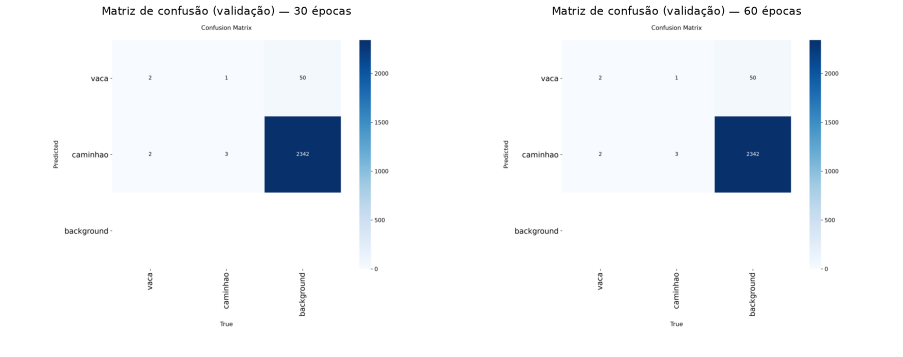

In [7]:
# Matriz de confusão gerada pela YOLO na validação de cada simulação
fig, eixos = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, ep in zip(eixos, EPOCAS):
    ax.imshow(Image.open(experimentos[ep]["pasta"] / "confusion_matrix.png"))
    ax.set_title(f"Matriz de confusão (validação) — {ep} épocas"); ax.axis("off")
plt.tight_layout(); plt.show()

### 3.3 Imagens de teste processadas pelo modelo

Cada imagem de teste é passada pelo modelo final de cada simulação. As caixas mostram a classe prevista e a confiança.
As imagens também são gravadas em `resultados/teste_yolo_custom_<épocas>ep/` para os prints da apresentação ao cliente.

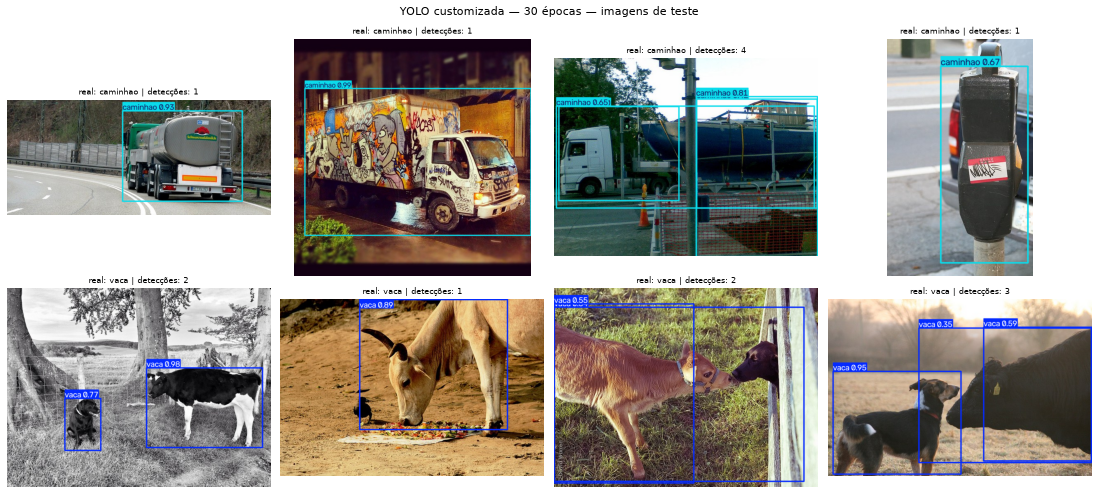

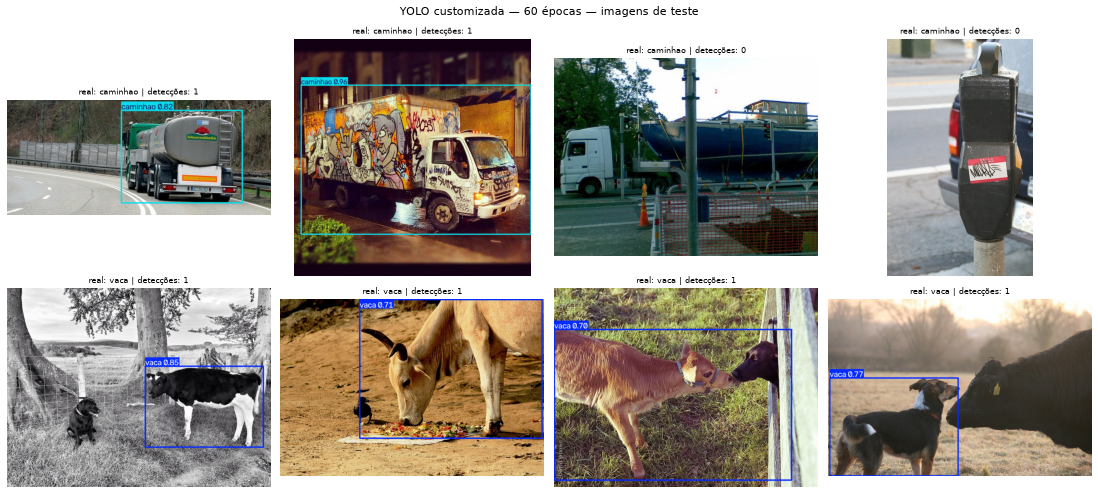

In [8]:
def mostrar_predicoes(modelo, titulo, pasta_saida, conf=0.25, classes=None):
    """Roda a detecção nas 8 imagens de teste, salva e exibe as imagens anotadas."""
    pasta_saida.mkdir(parents=True, exist_ok=True)
    fig, eixos = plt.subplots(2, 4, figsize=(17, 8))
    for ax, caminho in zip(eixos.ravel(), IMAGENS_TESTE):
        r = modelo.predict(str(caminho), imgsz=IMG, conf=conf, classes=classes, device=DEVICE, verbose=False)[0]
        anotada = Image.fromarray(r.plot()[:, :, ::-1])       # r.plot() devolve BGR; invertemos para RGB
        anotada.save(pasta_saida / caminho.name)              # print para o cliente
        ax.imshow(anotada); ax.axis("off")
        ax.set_title(f"real: {caminho.stem.split('_')[0]} | detecções: {len(r.boxes)}", fontsize=9)
    plt.suptitle(titulo); plt.tight_layout(); plt.show()

for ep in EPOCAS:
    mostrar_predicoes(experimentos[ep]["modelo"], f"YOLO customizada — {ep} épocas — imagens de teste",
                      REPO / "resultados" / f"teste_yolo_custom_{ep}ep")

In [9]:
# Conclusão numérica da Entrega 1, escrita a partir dos valores medidos acima
a, b = EPOCAS
ea, eb = experimentos[a], experimentos[b]
melhor = b if eb["test"].box.map50 >= ea["test"].box.map50 else a
MELHOR_EP = melhor
display(Markdown(f"""
### 3.4 Conclusões da Entrega 1 (valores desta execução)

| | {a} épocas | {b} épocas |
|---|---|---|
| mAP50 validação | {ea['val'].box.map50:.3f} | {eb['val'].box.map50:.3f} |
| mAP50 teste | {ea['test'].box.map50:.3f} | {eb['test'].box.map50:.3f} |
| mAP50-95 teste | {ea['test'].box.map:.3f} | {eb['test'].box.map:.3f} |
| precisão / recall no teste | {ea['test'].box.mp:.2f} / {ea['test'].box.mr:.2f} | {eb['test'].box.mp:.2f} / {eb['test'].box.mr:.2f} |
| erro final `val/box_loss` | {ea['hist']['val/box_loss'].iloc[-1]:.3f} | {eb['hist']['val/box_loss'].iloc[-1]:.3f} |
| tempo de treino | {ea['treino_s']:.0f} s | {eb['treino_s']:.0f} s |
| inferência | {ea['latencia_ms']:.1f} ms/imagem | {eb['latencia_ms']:.1f} ms/imagem |

- **Acurácia:** no teste, a simulação de **{melhor} épocas** teve o maior mAP50
  ({experimentos[melhor]['test'].box.map50:.3f}). A diferença de mAP50 entre as duas no teste foi de
  {abs(eb['test'].box.map50 - ea['test'].box.map50):.3f}.
- **Erro:** o `val/box_loss` final foi {ea['hist']['val/box_loss'].iloc[-1]:.3f} com {a} épocas e
  {eb['hist']['val/box_loss'].iloc[-1]:.3f} com {b} épocas.
- **Desempenho:** dobrar as épocas custou {eb['treino_s'] / ea['treino_s']:.1f}× o tempo de treino
  ({ea['treino_s']:.0f} s → {eb['treino_s']:.0f} s). O tempo de inferência praticamente não muda, porque a
  arquitetura é a mesma — só os pesos diferem.
- **Por que `last.pt` e não `best.pt`:** a YOLO salvou como `best.pt` a época {ea['melhor_epoca']} (simulação de {a}) e a
  época {eb['melhor_epoca']} (simulação de {b}). Quando o melhor ponto da validação cai logo no início, o `best.pt` é
  praticamente o modelo de partida e não mostra o efeito das épocas; por isso avaliamos os pesos do fim do treino.
  As curvas da seção 3.1 mostram a queda de acurácia nas primeiras épocas e a recuperação ao longo do treino.
- **Cuidado na leitura:** validação e teste têm **8 imagens cada**; um único acerto ou erro desloca as métricas
  em vários pontos percentuais. As diferenças entre 30 e 60 épocas devem ser lidas como tendência, não como medida precisa.
"""))


### 3.4 Conclusões da Entrega 1 (valores desta execução)

| | 30 épocas | 60 épocas |
|---|---|---|
| mAP50 validação | 0.871 | 0.870 |
| mAP50 teste | 0.819 | 0.849 |
| mAP50-95 teste | 0.562 | 0.572 |
| precisão / recall no teste | 0.56 / 1.00 | 0.72 / 0.88 |
| erro final `val/box_loss` | 1.317 | 1.591 |
| tempo de treino | 207 s | 390 s |
| inferência | 20.2 ms/imagem | 19.8 ms/imagem |

- **Acurácia:** no teste, a simulação de **60 épocas** teve o maior mAP50
  (0.849). A diferença de mAP50 entre as duas no teste foi de
  0.031.
- **Erro:** o `val/box_loss` final foi 1.317 com 30 épocas e
  1.591 com 60 épocas.
- **Desempenho:** dobrar as épocas custou 1.9× o tempo de treino
  (207 s → 390 s). O tempo de inferência praticamente não muda, porque a
  arquitetura é a mesma — só os pesos diferem.
- **Por que `last.pt` e não `best.pt`:** a YOLO salvou como `best.pt` a época 1 (simulação de 30) e a
  época 1 (simulação de 60). Quando o melhor ponto da validação cai logo no início, o `best.pt` é
  praticamente o modelo de partida e não mostra o efeito das épocas; por isso avaliamos os pesos do fim do treino.
  As curvas da seção 3.1 mostram a queda de acurácia nas primeiras épocas e a recuperação ao longo do treino.
- **Cuidado na leitura:** validação e teste têm **8 imagens cada**; um único acerto ou erro desloca as métricas
  em vários pontos percentuais. As diferenças entre 30 e 60 épocas devem ser lidas como tendência, não como medida precisa.


## 4. Entrega 2 — YOLO padrão (pré-treinada, sem customização)

Aqui usamos a mesma `yolov8n`, mas **como vem de fábrica**: treinada nas 80 classes do COCO, sem nenhum ajuste na
nossa base. As duas classes que escolhemos existem no COCO (`cow` = 19 e `truck` = 7), o que permite uma comparação
**quantitativa** justa: avaliamos a YOLO padrão nas mesmas 8 imagens de teste, mapeando `cow → vaca` e `truck → caminhao`.

> Observação honesta: como as imagens vêm do COCO, a YOLO padrão pode já ter visto algumas delas no próprio
> treinamento. Isso favorece a YOLO padrão nesta comparação e está registrado nas limitações.

Ultralytics 8.4.177 🚀 Python-3.12.3 torch-2.14.1+cpu CPU (AMD Ryzen 7 5700X 8-Core Processor)


YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2435.4±1192.4 MB/s, size: 79.7 KB)


val: Scanning ./runs/teste_indices_coco/labels/test... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 1.1Kit/s 0.0s

val: New cache created: ./runs/teste_indices_coco/labels/test.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.9it/s 0.3s

                   all          8          8      0.805      0.865      0.857      0.789


Speed: 1.3ms preprocess, 27.3ms inference, 0.0ms loss, 0.4ms postprocess per image


YOLO padrão no teste -> precisão 0.805 | recall 0.865 | mAP50 0.857 | mAP50-95 0.789 | 23.7 ms/imagem


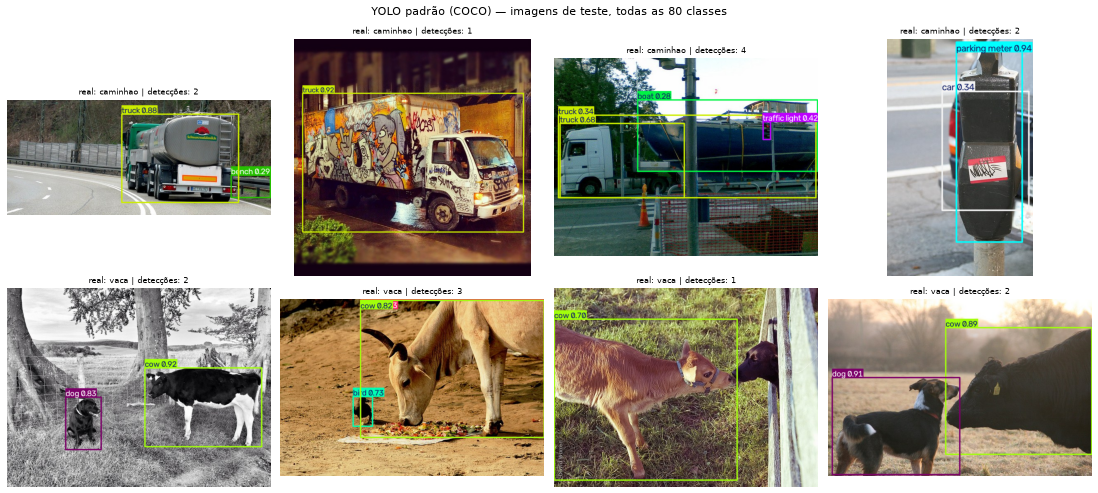

In [10]:
yolo_padrao = YOLO("yolov8n.pt")                    # pesos originais COCO, sem treino adicional
COCO_ID = {"vaca": 19, "caminhao": 7}               # índice das nossas classes no COCO

# Monta uma cópia do conjunto de teste com os rótulos no índice do COCO, para a avaliação padrão da Ultralytics
TESTE_COCO = RUNS / "teste_indices_coco"
shutil.rmtree(TESTE_COCO, ignore_errors=True)
(TESTE_COCO / "images" / "test").mkdir(parents=True); (TESTE_COCO / "labels" / "test").mkdir(parents=True)
for img in IMAGENS_TESTE:
    shutil.copy(img, TESTE_COCO / "images" / "test" / img.name)
    linhas_rot = (DATASET / "labels" / "test" / (img.stem + ".txt")).read_text().split("\n")
    nova = [" ".join([str(COCO_ID[CLASSES[int(l.split()[0])]])] + l.split()[1:]) for l in linhas_rot if l.strip()]
    (TESTE_COCO / "labels" / "test" / (img.stem + ".txt")).write_text("\n".join(nova) + "\n")
nomes_coco = "\n".join(f"  {i}: {n}" for i, n in yolo_padrao.names.items())
(RUNS / "data_teste_coco.yaml").write_text(
    f"path: {TESTE_COCO}\ntrain: images/test\nval: images/test\ntest: images/test\nnames:\n{nomes_coco}\n")

# Avalia somente as duas classes de interesse
m_padrao = yolo_padrao.val(data=str(RUNS / "data_teste_coco.yaml"), split="test", imgsz=IMG, device=DEVICE,
                           classes=list(COCO_ID.values()), verbose=False, plots=False,
                           project=str(RUNS), name="aval_yolo_padrao_test", exist_ok=True)
lat_padrao = medir_latencia(lambda c: yolo_padrao.predict(str(c), imgsz=IMG, device=DEVICE, verbose=False),
                            IMAGENS_TESTE)
print(f"YOLO padrão no teste -> precisão {m_padrao.box.mp:.3f} | recall {m_padrao.box.mr:.3f} | "
      f"mAP50 {m_padrao.box.map50:.3f} | mAP50-95 {m_padrao.box.map:.3f} | {lat_padrao:.1f} ms/imagem")

mostrar_predicoes(yolo_padrao, "YOLO padrão (COCO) — imagens de teste, todas as 80 classes",
                  REPO / "resultados" / "teste_yolo_padrao")

## 5. Entrega 2 — CNN treinada do zero (classificação)

A CNN responde a uma pergunta mais simples que a YOLO: **"esta imagem é de vaca ou de caminhão?"** — sem localizar o
objeto. Por isso não usa as caixas: o rótulo é só a classe da imagem (vem do nome do arquivo).

- **Arquitetura** (definida pelo Humberto para o grupo): 3 blocos `Conv2D 3×3 → BatchNorm → ReLU → MaxPool`
  (16, 32 e 64 filtros), `Dropout 0,3`, camada densa de 64 neurônios e saída com 2 classes. Entrada 64×64 RGB.
- **Treino do zero:** pesos iniciais aleatórios, sem nenhum pré-treino, nas mesmas 64 imagens de treino.

In [11]:
import torch.nn as nn

def carregar_split(split, tamanho=64):
    """Lê as imagens do split, redimensiona para 64x64 e devolve tensores (X, y) e arrays NumPy."""
    xs, ys = [], []
    for indice, classe in enumerate(CLASSES):
        for p in sorted((DATASET / "images" / split).glob(f"{classe}_*.jpg")):
            img = Image.open(p).convert("RGB").resize((tamanho, tamanho))
            xs.append(np.asarray(img, dtype=np.float32) / 255.0)   # normaliza para [0, 1]
            ys.append(indice)                                        # 0 = vaca, 1 = caminhao
    return np.stack(xs), np.array(ys, dtype=np.int64)

x_tr, y_tr = carregar_split("train"); x_va, y_va = carregar_split("val"); x_te, y_te = carregar_split("test")
para_tensor = lambda x: torch.from_numpy(x).permute(0, 3, 1, 2)     # (N, H, W, C) -> (N, C, H, W)

class FarmTechCNN(nn.Module):
    """CNN do zero para classificar vaca x caminhao (arquitetura do grupo, autoria do Humberto)."""
    def __init__(self, num_classes=2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(inplace=True), nn.MaxPool2d(2),   # 64 -> 32
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2),  # 32 -> 16
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2),  # 16 -> 8
        )
        self.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(64 * 8 * 8, 64), nn.ReLU(inplace=True),
                                        nn.Linear(64, num_classes))
    def forward(self, x):
        return self.classifier(torch.flatten(self.features(x), 1))

torch.manual_seed(SEED)
cnn = FarmTechCNN()
otimizador = torch.optim.Adam(cnn.parameters(), lr=1e-3)
criterio = nn.CrossEntropyLoss()
EPOCAS_CNN = 3 if FAST else 40
Xtr, Ytr, Xva, Yva, Xte, Yte = para_tensor(x_tr), torch.from_numpy(y_tr), para_tensor(x_va), torch.from_numpy(y_va), para_tensor(x_te), torch.from_numpy(y_te)

hist_cnn = {"loss_treino": [], "loss_val": [], "acc_treino": [], "acc_val": []}
inicio = time.perf_counter()
for epoca in range(EPOCAS_CNN):
    cnn.train()
    ordem = torch.randperm(len(Xtr))                      # embaralha as imagens a cada época
    for i in range(0, len(Xtr), 16):                      # mini-lotes de 16
        idx = ordem[i:i + 16]
        lote = Xtr[idx]
        espelhar = torch.rand(len(idx)) < 0.5             # aumento de dados: espelhamento horizontal
        lote = torch.where(espelhar[:, None, None, None], lote.flip(3), lote)
        otimizador.zero_grad()
        perda = criterio(cnn(lote), Ytr[idx])
        perda.backward(); otimizador.step()
    cnn.eval()
    with torch.no_grad():                                 # métricas da época em treino e validação
        s_tr, s_va = cnn(Xtr), cnn(Xva)
        hist_cnn["loss_treino"].append(criterio(s_tr, Ytr).item()); hist_cnn["loss_val"].append(criterio(s_va, Yva).item())
        hist_cnn["acc_treino"].append((s_tr.argmax(1) == Ytr).float().mean().item())
        hist_cnn["acc_val"].append((s_va.argmax(1) == Yva).float().mean().item())
treino_cnn_s = time.perf_counter() - inicio

with torch.no_grad():
    pred_cnn = cnn(Xte).argmax(1).numpy()                 # predição nas 8 imagens de teste
    cnn(Xte[:1])                                          # aquecimento
    t0 = time.perf_counter()
    for _ in range(20):
        for i in range(len(Xte)):
            cnn(Xte[i:i + 1])                             # uma imagem por vez, como em produção
    lat_cnn = (time.perf_counter() - t0) * 1000 / (20 * len(Xte))
acc_cnn = float((pred_cnn == y_te).mean())
print(f"CNN do zero -> {EPOCAS_CNN} épocas em {treino_cnn_s:.1f} s | acurácia treino {hist_cnn['acc_treino'][-1]:.2%} | "
      f"validação {hist_cnn['acc_val'][-1]:.2%} | teste {acc_cnn:.2%} | {lat_cnn:.2f} ms/imagem")

CNN do zero -> 40 épocas em 2.4 s | acurácia treino 100.00% | validação 75.00% | teste 87.50% | 0.48 ms/imagem


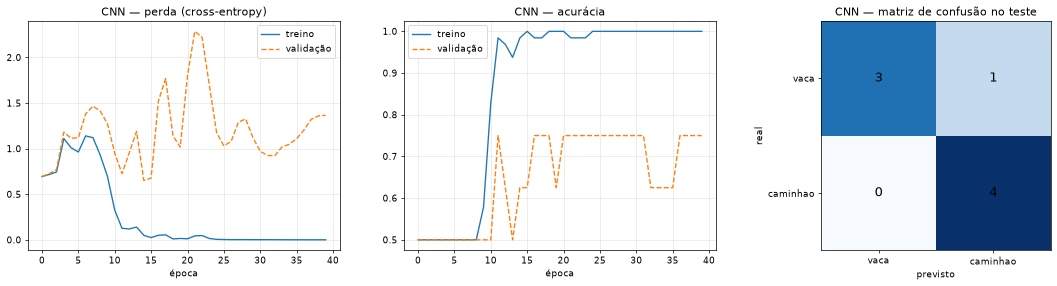

In [12]:
from sklearn.metrics import confusion_matrix

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.5))
ax1.plot(hist_cnn["loss_treino"], label="treino"); ax1.plot(hist_cnn["loss_val"], "--", label="validação")
ax1.set_title("CNN — perda (cross-entropy)"); ax1.set_xlabel("época"); ax1.legend(); ax1.grid(alpha=.3)
ax2.plot(hist_cnn["acc_treino"], label="treino"); ax2.plot(hist_cnn["acc_val"], "--", label="validação")
ax2.set_title("CNN — acurácia"); ax2.set_xlabel("época"); ax2.legend(); ax2.grid(alpha=.3)
mc = confusion_matrix(y_te, pred_cnn, labels=[0, 1])      # linhas = classe real, colunas = classe prevista
ax3.imshow(mc, cmap="Blues")
for (i, j), v in np.ndenumerate(mc):
    ax3.text(j, i, str(v), ha="center", va="center", fontsize=14)
ax3.set_xticks([0, 1]); ax3.set_xticklabels(CLASSES); ax3.set_yticks([0, 1]); ax3.set_yticklabels(CLASSES)
ax3.set_xlabel("previsto"); ax3.set_ylabel("real"); ax3.set_title("CNN — matriz de confusão no teste")
plt.tight_layout(); plt.show()

### 5.1 Motor NumPy do grupo (referência didática)

O Humberto também implementou uma CNN **sem framework**, só com NumPy (`cnn_numpy_humberto.py`): 4 filtros 3×3 fixos,
ReLU, max-pooling e uma camada densa treinável. Ela serve para mostrar a mecânica de uma convolução; rodamos na mesma
base real para registrar o resultado.

In [13]:
from cnn_numpy_humberto import NumpyCNNClassifier

cnn_np = NumpyCNNClassifier(input_shape=(64, 64, 3), num_classes=2, random_state=SEED)
hist_np = cnn_np.fit(x_tr, y_tr, x_va, y_va, epochs=3 if FAST else 25, lr=0.015)   # treino da camada densa
met_np = cnn_np.evaluate(x_te, y_te)                                                # avaliação no teste
print(f"CNN NumPy -> treino {hist_np.training_time_seconds:.1f} s | acurácia validação {hist_np.val_acc[-1]:.2%} | "
      f"teste {met_np.accuracy:.2%} | {met_np.inference_latency_ms:.1f} ms/imagem")

CNN NumPy -> treino 1.5 s | acurácia validação 62.50% | teste 50.00% | 23.1 ms/imagem


## 6. Comparação crítica das abordagens

Critérios do enunciado: facilidade de uso/integração, precisão, tempo de treinamento e tempo de inferência.
Todos os tempos foram medidos na mesma máquina desta execução.

,abordagem,tarefa,métrica no teste,treino (s),inferência (ms/img),facilidade de uso
0,YOLO customizada (60 épocas),detecção (classe + caixa),mAP50 = 0.849,389.9,19.80,Média: exige caixa rotulada em cada imagem; o treino é uma chamada (model.train)
1,"YOLO padrão (COCO, sem treino)",detecção (80 classes genéricas),mAP50 = 0.857,0.0,23.70,Alta: sem rotulação nem treino; só funciona se a classe existir no COCO
2,CNN do zero (40 épocas),classificação (só a classe),acurácia = 0.875,2.4,0.48,Alta para rotular (uma pasta/nome por classe); exige definir e ajustar a arquitetura
3,CNN NumPy (didática),classificação (só a classe),acurácia = 0.500,1.5,23.10,"Baixa: tudo implementado à mão; útil para ensino, não para produção"


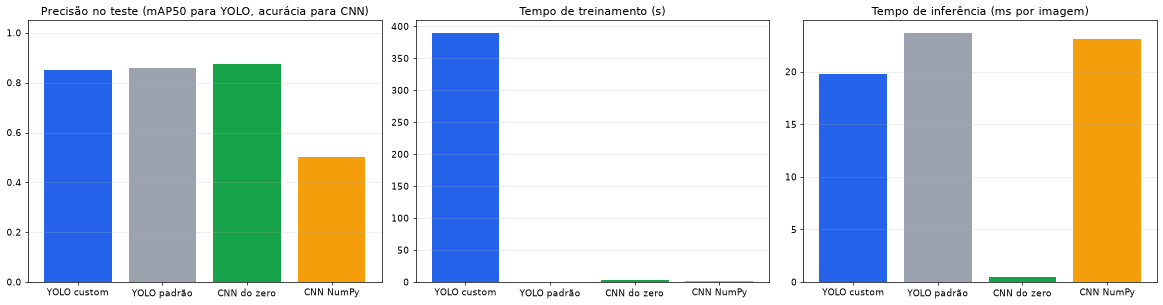

In [14]:
eb = experimentos[MELHOR_EP]
comparacao = pd.DataFrame([
    {"abordagem": f"YOLO customizada ({MELHOR_EP} épocas)", "tarefa": "detecção (classe + caixa)",
     "métrica no teste": f"mAP50 = {eb['test'].box.map50:.3f}", "valor": eb["test"].box.map50,
     "treino (s)": round(eb["treino_s"], 1), "inferência (ms/img)": round(eb["latencia_ms"], 1),
     "facilidade de uso": "Média: exige caixa rotulada em cada imagem; o treino é uma chamada (model.train)"},
    {"abordagem": "YOLO padrão (COCO, sem treino)", "tarefa": "detecção (80 classes genéricas)",
     "métrica no teste": f"mAP50 = {m_padrao.box.map50:.3f}", "valor": m_padrao.box.map50,
     "treino (s)": 0.0, "inferência (ms/img)": round(lat_padrao, 1),
     "facilidade de uso": "Alta: sem rotulação nem treino; só funciona se a classe existir no COCO"},
    {"abordagem": f"CNN do zero ({EPOCAS_CNN} épocas)", "tarefa": "classificação (só a classe)",
     "métrica no teste": f"acurácia = {acc_cnn:.3f}", "valor": acc_cnn,
     "treino (s)": round(treino_cnn_s, 1), "inferência (ms/img)": round(lat_cnn, 2),
     "facilidade de uso": "Alta para rotular (uma pasta/nome por classe); exige definir e ajustar a arquitetura"},
    {"abordagem": "CNN NumPy (didática)", "tarefa": "classificação (só a classe)",
     "métrica no teste": f"acurácia = {met_np.accuracy:.3f}", "valor": met_np.accuracy,
     "treino (s)": round(hist_np.training_time_seconds, 1), "inferência (ms/img)": round(met_np.inference_latency_ms, 1),
     "facilidade de uso": "Baixa: tudo implementado à mão; útil para ensino, não para produção"},
])
(REPO / "resultados").mkdir(exist_ok=True)
comparacao.drop(columns="valor").to_csv(REPO / "resultados" / "comparacao_abordagens.csv", index=False)
pd.set_option("display.max_colwidth", None)
display(comparacao.drop(columns="valor"))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4.8))
cores = ["#2563EB", "#9CA3AF", "#16A34A", "#F59E0B"]
rotulos = ["YOLO custom", "YOLO padrão", "CNN do zero", "CNN NumPy"]
ax1.bar(rotulos, comparacao["valor"], color=cores); ax1.set_ylim(0, 1.05)
ax1.set_title("Precisão no teste (mAP50 para YOLO, acurácia para CNN)")
ax2.bar(rotulos, comparacao["treino (s)"], color=cores); ax2.set_title("Tempo de treinamento (s)")
ax3.bar(rotulos, comparacao["inferência (ms/img)"], color=cores); ax3.set_title("Tempo de inferência (ms por imagem)")
for ax in (ax1, ax2, ax3):
    ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(REPO / "resultados" / "comparacao_abordagens.png", dpi=110); plt.show()

In [15]:
display(Markdown(f"""
### 6.1 Leitura crítica (valores desta execução)

**Atenção à métrica:** mAP50 (YOLO) e acurácia (CNN) **não são a mesma régua**. A YOLO precisa acertar a classe *e*
posicionar a caixa com IoU ≥ 0,5; a CNN só precisa acertar a classe da imagem inteira, e com 2 classes o acaso já dá 50%.

1. **Facilidade de uso/integração.** A YOLO padrão é a mais simples (zero rotulação, zero treino), mas só serve porque
   `vaca` e `caminhao` existem no COCO; para um objeto específico do cliente ela não teria a classe. A YOLO customizada
   exige o trabalho mais caro do projeto — desenhar a caixa em cada imagem — e depois o treino é uma linha de código.
   A CNN é a mais barata de rotular (só a classe), mas a arquitetura e os hiperparâmetros ficam por nossa conta.
2. **Precisão.** YOLO customizada ({MELHOR_EP} épocas): mAP50 = **{eb['test'].box.map50:.3f}** no teste.
   YOLO padrão: mAP50 = **{m_padrao.box.map50:.3f}**. CNN do zero: acurácia = **{acc_cnn:.3f}**
   (treino {hist_cnn['acc_treino'][-1]:.2f}, validação {hist_cnn['acc_val'][-1]:.2f}). CNN NumPy: acurácia = **{met_np.accuracy:.3f}**.
   Entre as duas YOLO, a {'customizada' if eb['test'].box.map50 > m_padrao.box.map50 else 'padrão'} teve o maior mAP50 no teste
   (diferença de {abs(eb['test'].box.map50 - m_padrao.box.map50):.3f}): com apenas 64 imagens de treino, o ajuste fino
   {'superou' if eb['test'].box.map50 > m_padrao.box.map50 else 'não superou'} um modelo treinado em mais de 100 mil imagens que já continham essas classes.
3. **Tempo de treinamento.** YOLO customizada: **{eb['treino_s']:.0f} s**; CNN do zero: **{treino_cnn_s:.1f} s**;
   CNN NumPy: **{hist_np.training_time_seconds:.1f} s**; YOLO padrão: não se aplica. A CNN treina
   {eb['treino_s'] / max(treino_cnn_s, 1e-9):.0f}× mais rápido porque tem muito menos parâmetros e entrada 64×64.
4. **Tempo de inferência.** YOLO customizada: **{eb['latencia_ms']:.1f} ms**/imagem; YOLO padrão: **{lat_padrao:.1f} ms**;
   CNN do zero: **{lat_cnn:.2f} ms**; CNN NumPy: **{met_np.inference_latency_ms:.1f} ms** (laços em Python puro).
   As duas YOLO têm a mesma arquitetura, então a latência é equivalente.
"""))


### 6.1 Leitura crítica (valores desta execução)

**Atenção à métrica:** mAP50 (YOLO) e acurácia (CNN) **não são a mesma régua**. A YOLO precisa acertar a classe *e*
posicionar a caixa com IoU ≥ 0,5; a CNN só precisa acertar a classe da imagem inteira, e com 2 classes o acaso já dá 50%.

1. **Facilidade de uso/integração.** A YOLO padrão é a mais simples (zero rotulação, zero treino), mas só serve porque
   `vaca` e `caminhao` existem no COCO; para um objeto específico do cliente ela não teria a classe. A YOLO customizada
   exige o trabalho mais caro do projeto — desenhar a caixa em cada imagem — e depois o treino é uma linha de código.
   A CNN é a mais barata de rotular (só a classe), mas a arquitetura e os hiperparâmetros ficam por nossa conta.
2. **Precisão.** YOLO customizada (60 épocas): mAP50 = **0.849** no teste.
   YOLO padrão: mAP50 = **0.857**. CNN do zero: acurácia = **0.875**
   (treino 1.00, validação 0.75). CNN NumPy: acurácia = **0.500**.
   Entre as duas YOLO, a padrão teve o maior mAP50 no teste
   (diferença de 0.008): com apenas 64 imagens de treino, o ajuste fino
   não superou um modelo treinado em mais de 100 mil imagens que já continham essas classes.
3. **Tempo de treinamento.** YOLO customizada: **390 s**; CNN do zero: **2.4 s**;
   CNN NumPy: **1.5 s**; YOLO padrão: não se aplica. A CNN treina
   166× mais rápido porque tem muito menos parâmetros e entrada 64×64.
4. **Tempo de inferência.** YOLO customizada: **19.8 ms**/imagem; YOLO padrão: **23.7 ms**;
   CNN do zero: **0.48 ms**; CNN NumPy: **23.1 ms** (laços em Python puro).
   As duas YOLO têm a mesma arquitetura, então a latência é equivalente.


## 7. Conclusões, pontos fortes e limitações

**Qual abordagem para qual necessidade do cliente**

- **Precisa saber *onde* está o objeto** (contar animais, acionar alerta quando um caminhão cruza a porteira):
  é tarefa de detecção — YOLO. Se a classe já existe no COCO, a YOLO padrão resolve sem custo de rotulação; se o objeto
  é específico do cliente (uma praga, um equipamento, um documento), só a YOLO customizada atende.
- **Basta saber *o que* aparece na imagem** e o hardware é limitado (ESP32-CAM, Raspberry Pi): a CNN é ordens de
  grandeza mais leve e rápida, mas com 64 imagens de treino ela generaliza pior, como mostram a distância entre a
  acurácia de treino e a de validação/teste.

**Pontos fortes do trabalho**

- Pipeline completo e reproduzível: a mesma base de 80 imagens reais alimenta as três abordagens, com semente fixa.
- Todos os números da comparação foram medidos na mesma execução e na mesma máquina.
- Duas simulações de épocas com curvas de erro, métricas de validação e teste e imagens de teste processadas.

**Limitações**

- **Rotulação:** as caixas vêm das anotações originais do COCO, não foram desenhadas por nós no Make Sense AI.
- **Base pequena:** 8 imagens de validação e 8 de teste; as métricas têm alta variância e não sustentam afirmações finas.
- **Vantagem da YOLO padrão:** as imagens são do COCO, conjunto no qual a YOLO padrão foi treinada; em fotos novas da
  fazenda do cliente a diferença para a customizada pode ser outra. Pelo mesmo motivo, a YOLO customizada parte de pesos
  que já conheciam as duas classes (é um ajuste fino, não um aprendizado do zero).
- **Métricas diferentes:** mAP50 e acurácia não são diretamente comparáveis.
- **Próximos passos:** fotografar o cenário real do cliente, rotular no Make Sense AI, ampliar validação/teste e repetir as medições.